# Лабораторная работа №3
## Исследование решающих деревьев

**Цель:** повторить пункты 2–4 первой работы: обучить деревья sklearn для классификации и регрессии, проверить улучшения на CV, самостоятельно реализовать CART, перенести выбранные улучшения и сравнить результаты.

Условия из [первой](research-1.ipynb) и [второй](research-2.ipynb) работ:
- [Steam Game Hits](https://www.kaggle.com/datasets/vedauv/what-makes-a-steam-game-a-hit-8000-games): классификация `hit`, основная метрика **Average Precision (AP)**; дополнительные — F1, precision, recall, balanced accuracy, ROC AUC и accuracy. Порог >0.5; при равенстве выбираем класс 0. AP оценивает ранжирование редкого класса без привязки к одному порогу.
- [Video Games Sales](https://www.kaggle.com/datasets/ulrikthygepedersen/video-games-sales): регрессия `global_sales` в **миллионах копий**; основная метрика **MAE**, дополнительные — RMSE и R². MAE интерпретируема в единицах продаж, RMSE выделяет ошибки на крупных релизах.

Steam-набор **синтетический**: `hit=1` означает верхние 20% по выручке; закономерности относятся к генератору. В признаках нет выручки, числа владельцев, отзывов и других результатов после релиза. Wishlist автор обозначил как дорелизный; доступность остальных характеристик до релиза — допущение учебного сценария. Для продаж исключены ранг и региональные продажи, почти раскрывающие ответ; название используется только для разбиения по группам. Продажи накоплены к моменту сбора и не имеют единого горизонта наблюдения.

Разбиения повторяют предыдущие работы: seed=42, train/test 80/20, стратификация Steam, разделение продаж по названию игры и 3-fold CV внутри train. Все преобразователи обучаются внутри Pipeline на train-fold. Тест не участвует в выборе гипотез и параметров. Ноутбук самодостаточен, выполняется из корня проекта; зависимости не изменились. Пояснения находятся в Markdown-ячейках, без комментариев внутри кода. Отдельно сохраняются только две таблицы в `results/research-3/`.

### Импорт и воспроизводимость
Используем существующее окружение, фиксируем seed и ограничиваем число потоков. Поиск параметров выполняется последовательно, без фоновых процессов joblib.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
from pathlib import Path
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedKFold, GroupKFold, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score, PrecisionRecallDisplay, ConfusionMatrixDisplay)
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from threadpoolctl import threadpool_limits
SEED = 42
np.random.seed(SEED)
thread_limit = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
assert (ROOT / "data").exists(), "Откройте ноутбук из корня проекта"
RESULTS = ROOT / "results/research-3"
RESULTS.mkdir(parents=True, exist_ok=True)
print({"Python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "sklearn": sklearn.__version__})

{'Python': '3.14.8', 'numpy': '2.5.5', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


### Подготовка данных и неизменное разбиение
Повторяем очистку, белые списки признаков и разбиения предыдущих работ. Версии одной игры не пересекают train/test и CV-fold в задаче продаж. Пропуски в признаках остаются до обучения imputer внутри Pipeline.

In [2]:
steam = pd.read_csv(ROOT / "data/steam/steam_game_hits.csv")
sales = pd.read_csv(ROOT / "data/sales/video_games_sales.csv")
steam = steam.drop_duplicates().dropna(subset=["hit"]).reset_index(drop=True)
sales = sales.drop_duplicates().dropna(subset=["global_sales", "name"]).copy()
sales = sales.loc[np.isfinite(sales.global_sales) & (sales.global_sales >= 0)].reset_index(drop=True)
steam_num = ["release_year", "is_indie", "team_size", "price_usd", "has_multiplayer",
             "early_access", "controller_support", "languages_supported", "file_size_gb",
             "wishlists_k", "trailer_views_k"]
steam_cat = ["genre"]
sales_num, sales_cat = ["year"], ["platform", "genre", "publisher"]
Xc, yc = steam[steam_num + steam_cat].copy(), steam.hit.astype(int)
Xr, yr = sales[sales_num + sales_cat].copy(), sales.global_sales.astype(float)
groups = sales.name.str.normalize("NFKC").str.strip().str.casefold()
ic_train, ic_test = train_test_split(np.arange(len(Xc)), test_size=0.2,
                                     stratify=yc, random_state=SEED)
ir_train, ir_test = next(GroupShuffleSplit(n_splits=1, test_size=0.2,
                            random_state=SEED).split(Xr, yr, groups))
Xc_train, Xc_test, yc_train, yc_test = Xc.iloc[ic_train], Xc.iloc[ic_test], yc.iloc[ic_train], yc.iloc[ic_test]
Xr_train, Xr_test, yr_train, yr_test = Xr.iloc[ir_train], Xr.iloc[ir_test], yr.iloc[ir_train], yr.iloc[ir_test]
g_train, g_test = groups.iloc[ir_train], groups.iloc[ir_test]
assert not set(g_train) & set(g_test)
cv_c = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(Xc_train, yc_train))
cv_r = list(GroupKFold(3).split(Xr_train, yr_train, g_train))
for a, b in cv_r:
    assert not set(g_train.iloc[a]) & set(g_train.iloc[b])
display(pd.DataFrame({"Задача": ["Классификация", "Регрессия"],
    "train": [len(ic_train), len(ir_train)], "test": [len(ic_test), len(ir_test)]}))
print("Доля hit в train/test:", round(yc_train.mean(), 3), round(yc_test.mean(), 3))

,Задача,train,test
0,Классификация,6400,1600
1,Регрессия,13272,3326


Доля hit в train/test: 0.2 0.2


## 2. Создание бейзлайна и оценка качества
### 2a. Деревья sklearn
Базовая классификация — `DecisionTreeClassifier(criterion="gini")`, регрессия — `DecisionTreeRegressor(criterion="squared_error")`; глубина не ограничена, минимум в листе — 1. Фиксируем random_state. Это гибкие модели, склонные переобучаться.

Числа заполняем медианой, категории — наиболее частым значением и one-hot. Масштабирование не требуется: дерево проверяет порядок значений и пороги, а не расстояния. Неизвестные категории кодируются нулями. Полное one-hot допускается: линейная зависимость столбцов деревьям не мешает.

In [3]:
def prep(task, engineered=False):
    num = list(steam_num if task == "c" else sales_num)
    cat = list(steam_cat if task == "c" else sales_cat)
    if engineered:
        if task == "c":
            num += ["wishlist_per_team", "wishlist_trailer_ratio", "wishlist_price"]
        else:
            cat += ["platform_genre", "decade"]
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                     min_frequency=0.01 if engineered else None))]), cat)
    ], sparse_threshold=0)

def pipeline(task, model, engineered=False):
    steps = [("features", Features(task))] if engineered else []
    return Pipeline(steps + [("prep", prep(task, engineered)), ("model", model)])

def estimator(task, **params):
    cls = DecisionTreeClassifier if task == "c" else DecisionTreeRegressor
    return cls(random_state=SEED, **params)

base_c = pipeline("c", estimator("c")).fit(Xc_train, yc_train)
base_r = pipeline("r", estimator("r")).fit(Xr_train, yr_train)
print("Исходные деревья обучены.")

Исходные деревья обучены.


### 2b. Метрики исходных деревьев и Dummy
Dummy даёт ориентир: доля классов для AP, медиана продаж для MAE. Для деревьев дополнительно вычисляем train-метрики, число узлов, листьев и глубину. Разрыв train/test — диагностика переобучения, а не основание подбирать настройки по тесту. Регрессионное дерево предсказывает среднее неотрицательных ответов листа, поэтому не экстраполирует за диапазон train.

In [4]:
rows, predictions = [], {}
def evaluate(name, task, model):
    X, y = (Xc_test, yc_test) if task == "c" else (Xr_test, yr_test)
    start = time.perf_counter()
    if task == "c":
        prob = model.predict_proba(X)[:, 1]
        pred = (prob > 0.5).astype(int)
        metrics = {"AP": average_precision_score(y, prob), "ROC_AUC": roc_auc_score(y, prob),
            "F1": f1_score(y, pred, zero_division=0), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0), "Balanced_accuracy": balanced_accuracy_score(y, pred),
            "Accuracy": accuracy_score(y, pred)}
        predictions[(task, name)] = (pred, prob)
    else:
        pred = model.predict(X)
        metrics = {"MAE": mean_absolute_error(y, pred), "RMSE": np.sqrt(mean_squared_error(y, pred)),
                   "R2": r2_score(y, pred)}
        predictions[(task, name)] = pred
    rows.append({"task": task, "model": name, **metrics, "predict_seconds": time.perf_counter() - start})
    return pd.DataFrame([rows[-1]])


dummy_c = DummyClassifier(strategy="prior").fit(Xc_train, yc_train)
dummy_r = DummyRegressor(strategy="median").fit(Xr_train, yr_train)
for name, task, model in [("Dummy", "c", dummy_c), ("Dummy", "r", dummy_r),
                          ("sklearn baseline", "c", base_c), ("sklearn baseline", "r", base_r)]:
    display(evaluate(name, task, model))
for task, model, X, y in [("c", base_c, Xc_train, yc_train), ("r", base_r, Xr_train, yr_train)]:
    tree = model.named_steps["model"]
    score = average_precision_score(y, model.predict_proba(X)[:, 1]) if task == "c" else mean_absolute_error(y, model.predict(X))
    print(task, "Train AP" if task == "c" else "Train MAE", score,
          "глубина:", tree.get_depth(), "листьев:", tree.get_n_leaves(), "узлов:", tree.tree_.node_count)

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,Dummy,0.2,0.5,0.0,0.0,0.0,0.5,0.8,0.023107


,task,model,MAE,RMSE,R2,predict_seconds
0,r,Dummy,0.456185,1.616683,-0.051272,0.00426


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,sklearn baseline,0.337013,0.677344,0.483619,0.482866,0.484375,0.677344,0.793125,0.036917


,task,model,MAE,RMSE,R2,predict_seconds
0,r,sklearn baseline,0.533335,1.521646,0.068693,0.030494


c Train AP 1.0 глубина: 23 листьев: 783 узлов: 1565


r Train MAE 0.2142055517882258 глубина: 185 листьев: 8560 узлов: 17119


## 3. Улучшение бейзлайна
### 3a. Гипотезы
1. **H1 — подготовка и новые признаки.** Объединение редких категорий (<1% на train-fold) может уменьшить переобучение на редких издателях. Для Steam проверяем wishlist на размер команды, отношение wishlist/просмотров и произведение wishlist на цену — все вычисляются из исходных дорелизных признаков. Для продаж добавляем платформу–жанр и десятилетие: такие признаки могут уменьшить необходимую глубину.
2. **H2 — ограничение сложности.** Проверяем `max_depth` ∈ {3, 6, 10, None} и `min_samples_leaf` ∈ {5, 25, 75}, оставляя `min_samples_split=2`. Для классификации дополнительно проверяем {None, balanced} в `class_weight`. Крупные листья дают менее крайние вероятности; balanced не гарантирует роста AP.
3. **H3 — логарифм цели продаж.** Дерево для log1p продаж с expm1 на выходе меньше ориентируется на блокбастеры. Ошибки CV и теста всё равно измеряются в исходных миллионах копий. Обратное преобразование среднего логарифмов не равно среднему продаж: улучшение MAE может сопровождаться ухудшением RMSE.

Масштабирование и монотонное логарифмирование **признаков** не проверяем как отдельные улучшения: они не добавляют дереву новых порядков разбиения. Это отличается от логарифмирования **целевой переменной**, которое меняет оптимизируемую ошибку.

### 3b. Признаки и анализ train
Преобразователь не использует цель. Отношения и произведения задаются заранее; неизвестный год получает категорию unknown. Смотрим распределение цели и число категорий только на train.

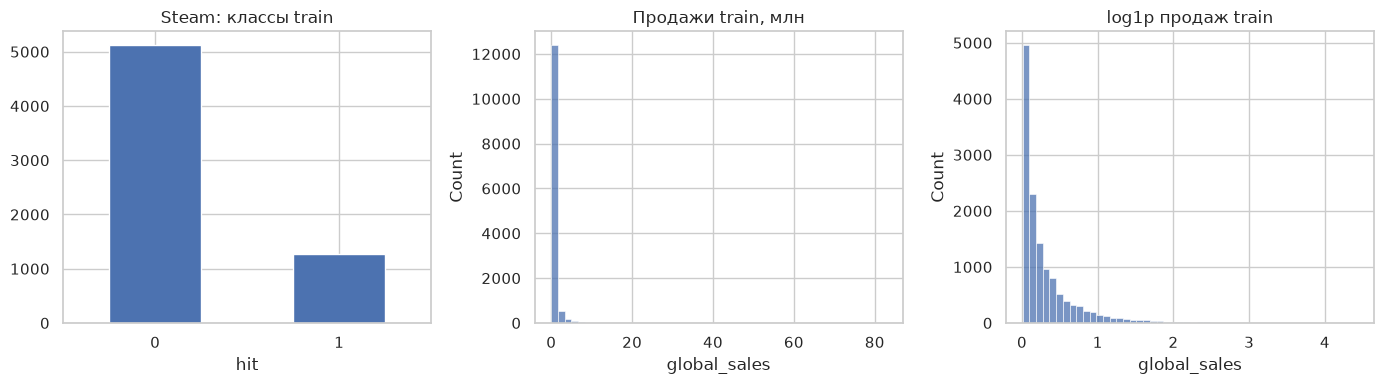

,Категорий в train
platform,30
genre,12
publisher,533


In [5]:
class Features(TransformerMixin, BaseEstimator):
    def __init__(self, task="c"):
        self.task = task
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        out = X.copy()
        if self.task == "c":
            out["wishlist_per_team"] = out.wishlists_k / (out.team_size + 1)
            out["wishlist_trailer_ratio"] = out.wishlists_k / (out.trailer_views_k + 1)
            out["wishlist_price"] = out.wishlists_k * out.price_usd
        else:
            out["platform_genre"] = out.platform.fillna("unknown") + " / " + out.genre.fillna("unknown")
            out["decade"] = ((out.year // 10) * 10).astype("Int64").astype("string").fillna("unknown").astype(object)
        return out

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
yc_train.value_counts().sort_index().plot.bar(ax=axes[0], rot=0, title="Steam: классы train")
sns.histplot(yr_train, bins=50, ax=axes[1]); axes[1].set_title("Продажи train, млн")
sns.histplot(np.log1p(yr_train), bins=50, ax=axes[2]); axes[2].set_title("log1p продаж train")
plt.tight_layout(); plt.show()
display(Xr_train[sales_cat].nunique().rename("Категорий в train").to_frame())

### 3b–3c. Проверка гипотез на CV и формирование улучшенного бейзлайна
H1 сравниваем с H0 без изменения параметров дерева. Чтобы ограничение сложности не зависело от успешности новых признаков, H2 ищет параметры отдельно для исходной и расширенной подготовки. H3 проверяем при расширенной подготовке с такой же сеткой сложности.

Все варианты оцениваем на одинаковых fold. Выбираем по AP для классификации и −MAE для регрессии: `score` всегда больше — лучше. `std` описывает разброс по fold, а не доверительный интервал. В финальном выборе участвует H0; выигрыш заранее не гарантирован. Сетки и их оценки выводим в ноутбуке, отдельные файлы для каждой сетки не создаём.

In [6]:
candidates, experiments, searches = {"c": {}, "r": {}}, [], {}
for task, X, y, folds, scoring in [("c", Xc_train, yc_train, cv_c, "average_precision"),
                                  ("r", Xr_train, yr_train, cv_r, "neg_mean_absolute_error")]:
    for name, model in [("H0 baseline", base_c if task == "c" else base_r),
                        ("H1 features", pipeline(task, estimator(task), True))]:
        scores = cross_val_score(model, X, y, cv=folds, scoring=scoring, n_jobs=1)
        candidates[task][name] = clone(model)
        experiments.append({"task": task, "experiment": name, "score": scores.mean(), "std": scores.std()})
    grid = {"model__max_depth": [3, 6, 10, None], "model__min_samples_leaf": [5, 25, 75]}
    if task == "c":
        grid["model__class_weight"] = [None, "balanced"]
    variants = [("H2 tuned raw", pipeline(task, estimator(task)), grid),
                ("H2 tuned features", pipeline(task, estimator(task), True), grid)]
    if task == "r":
        variants.append(("H3 tuned log target", TransformedTargetRegressor(
            regressor=pipeline(task, estimator(task), True), func=np.log1p, inverse_func=np.expm1),
            {"regressor__" + k: v for k, v in grid.items()}))
    for name, model, params in variants:
        search = GridSearchCV(model, params, cv=folds, scoring=scoring, n_jobs=1, refit=True, error_score="raise")
        search.fit(X, y)
        searches[(task, name)] = search
        candidates[task][name] = search.best_estimator_
        experiments.append({"task": task, "experiment": name, "score": search.best_score_,
                            "std": search.cv_results_["std_test_score"][search.best_index_]})
        print(task, name, search.best_params_)
        display(pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(5))
cv_table = pd.DataFrame(experiments)
display(cv_table)
cv_table.to_csv(RESULTS / "cv_experiments.csv", index=False)
for task in ["c", "r"]:
    tab = cv_table[cv_table.task == task].set_index("experiment")
    for name, reference in [("H1 features", "H0 baseline"), ("H2 tuned raw", "H0 baseline"),
                            ("H2 tuned features", "H1 features")]:
        gain = tab.loc[name, "score"] - tab.loc[reference, "score"]
        print(task, name, "минус", reference, round(gain, 5), "— поддержана по среднему CV" if gain > 0 else "— не поддержана")
    if task == "r":
        gain = tab.loc["H3 tuned log target", "score"] - tab.loc["H2 tuned features", "score"]
        print("r H3 минус H2 с признаками:", round(gain, 5))

c H2 tuned raw {'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__min_samples_leaf': 75}


,params,mean_test_score,std_test_score,rank_test_score
17,"{'model__class_weight': 'balanced', 'model__ma...",0.645009,0.022794,1
20,"{'model__class_weight': 'balanced', 'model__ma...",0.644977,0.022955,2
23,"{'model__class_weight': 'balanced', 'model__ma...",0.644977,0.022955,2
11,"{'model__class_weight': None, 'model__max_dept...",0.640520,0.016679,4
8,"{'model__class_weight': None, 'model__max_dept...",0.640520,0.016679,4


c H2 tuned features {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 75}


,params,mean_test_score,std_test_score,rank_test_score
20,"{'model__class_weight': 'balanced', 'model__ma...",0.641705,0.022444,1
23,"{'model__class_weight': 'balanced', 'model__ma...",0.641705,0.022444,1
17,"{'model__class_weight': 'balanced', 'model__ma...",0.641334,0.021005,3
11,"{'model__class_weight': None, 'model__max_dept...",0.634417,0.020086,4
8,"{'model__class_weight': None, 'model__max_dept...",0.634417,0.020086,4


r H2 tuned raw {'model__max_depth': None, 'model__min_samples_leaf': 25}


,params,mean_test_score,std_test_score,rank_test_score
10,"{'model__max_depth': None, 'model__min_samples...",-0.516888,0.006922,1
11,"{'model__max_depth': None, 'model__min_samples...",-0.520004,0.011763,2
9,"{'model__max_depth': None, 'model__min_samples...",-0.520934,0.007080,3
8,"{'model__max_depth': 10, 'model__min_samples_l...",-0.532206,0.010184,4
7,"{'model__max_depth': 10, 'model__min_samples_l...",-0.533708,0.003952,5


... (2 outputs left out)

r H3 tuned log target {'regressor__model__max_depth': None, 'regressor__model__min_samples_leaf': 25}


,params,mean_test_score,std_test_score,rank_test_score
10,"{'regressor__model__max_depth': None, 'regress...",-0.456941,0.012973,1
11,"{'regressor__model__max_depth': None, 'regress...",-0.460381,0.015098,2
7,"{'regressor__model__max_depth': 10, 'regressor...",-0.461444,0.013488,3
8,"{'regressor__model__max_depth': 10, 'regressor...",-0.462612,0.015982,4
4,"{'regressor__model__max_depth': 6, 'regressor_...",-0.467031,0.013497,5


,task,experiment,score,std
0,c,H0 baseline,0.356574,0.002529
1,c,H1 features,0.357055,0.008935
2,c,H2 tuned raw,0.645009,0.022794
3,c,H2 tuned features,0.641705,0.022444
4,r,H0 baseline,-0.580231,0.012347
5,r,H1 features,-0.594327,0.011932
6,r,H2 tuned raw,-0.516888,0.006922
7,r,H2 tuned features,-0.522741,0.006974
8,r,H3 tuned log target,-0.456941,0.012973


c H1 features минус H0 baseline 0.00048 — поддержана по среднему CV
c H2 tuned raw минус H0 baseline 0.28844 — поддержана по среднему CV
c H2 tuned features минус H1 features 0.28465 — поддержана по среднему CV
r H1 features минус H0 baseline -0.0141 — не поддержана
r H2 tuned raw минус H0 baseline 0.06334 — поддержана по среднему CV
r H2 tuned features минус H1 features 0.07159 — поддержана по среднему CV
r H3 минус H2 с признаками: 0.0658


### 3d–3g. Обучение выбранных моделей и оценка на тесте
Фиксируем победителя по CV и переобучаем на всём train. Положительный выигрыш ниже означает рост AP или снижение MAE. После просмотра тестовых результатов не меняем сетку, признаки и критерий выбора.

In [7]:
selected, improved = {}, {}
for task, X, y, metric in [("c", Xc_train, yc_train, "AP"), ("r", Xr_train, yr_train, "MAE")]:
    ranking = cv_table[cv_table.task == task].sort_values("score", ascending=False, kind="stable")
    selected[task] = ranking.iloc[0].experiment
    improved[task] = clone(candidates[task][selected[task]]).fit(X, y)
    print(task, "Выбрано:", selected[task])
    display(evaluate("sklearn improved", task, improved[task]))
    table = pd.DataFrame(rows).query("task == @task").set_index("model")
    a, b = table.loc["sklearn baseline", metric], table.loc["sklearn improved", metric]
    gain = b-a if task == "c" else a-b
    display(Markdown(f"**Вывод пункта 3 ({task}):** {metric}: {a:.5f} → {b:.5f}, выигрыш {gain:+.5f}. "
                     + ("Улучшение подтвердилось на тесте." if gain > 0 else "Улучшение на тесте не подтверждено.")))

c Выбрано: H2 tuned raw


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,sklearn improved,0.669748,0.885239,0.610245,0.474048,0.85625,0.809375,0.78125,0.033611


**Вывод пункта 3 (c):** AP: 0.33701 → 0.66975, выигрыш +0.33273. Улучшение подтвердилось на тесте.

r Выбрано: H3 tuned log target


,task,model,MAE,RMSE,R2,predict_seconds
0,r,sklearn improved,0.444971,1.504752,0.089258,0.026589


**Вывод пункта 3 (r):** MAE: 0.53334 → 0.44497, выигрыш +0.08836. Улучшение подтвердилось на тесте.

## 4. Собственная имплементация CART
### 4a. Алгоритм и критерии
Строим бинарное дерево сверху вниз. Для каждого непостоянного числового столбца сортируем значения и проверяем пороги между соседними **различными** значениями. Выбираем максимальное уменьшение взвешенной нечистоты. One-hot столбцы с двумя значениями обрабатываем напрямую, без сортировки. Кумулятивные суммы позволяют оценить все пороги одного признака за линейное время после сортировки.

Для классификации Gini=1−Σpₖ²; в листе хранятся взвешенные доли классов. Для регрессии нечистота — взвешенная дисперсия, прогноз — среднее ответов листа. Для `balanced` вес строки n/(K·n_class); ограничения `min_samples_leaf` и `min_samples_split` считаем по числу строк, а не сумме весов. Свободное дерево может делать разбиение с нулевым выигрышем, если оно допустимо: это необходимо, например, для XOR.

Остановка: чистый узел, достигнутая глубина, недостаток строк или отсутствие допустимых разбиений. Сохраняем узлы, пороги, число строк и уменьшение нечистоты. Поиск разбиений и предсказания реализованы на NumPy; sklearn используется только для интерфейса Pipeline и проверки входа.

При равном выигрыше собственная модель выбирает первый признак и первый порог. sklearn случайно переставляет признаки даже при `splitter="best"`, поэтому при ничьих деревья могут различаться. Вход переводим в float32, как в sklearn, а суммы считаем в float64. Численные допуски также могут влиять на почти равные разбиения. На реальных данных не требуем полного совпадения двух деревьев; корректность проверяем отдельно на контролируемых примерах.

В одном узле полный поиск требует примерно O(d·n·log n), память для временных массивов — O(d·n). Предсказание одной строки проходит путь длины, равной глубине дерева; полное дерево хранится в списке узлов. Отсечение по стоимости сложности (ccp_alpha), случайный выбор признаков и другие варианты CART здесь не реализованы и не используются в сравнении.

In [8]:
class NumpyCART(BaseEstimator):
    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1, class_weight=None):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.class_weight = class_weight
    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=np.float32)
        if self.max_depth is not None and (not isinstance(self.max_depth, (int, np.integer)) or self.max_depth < 1):
            raise ValueError("max_depth: None или положительное целое")
        for name, value, minimum in [("min_samples_split", self.min_samples_split, 2), ("min_samples_leaf", self.min_samples_leaf, 1)]:
            if not isinstance(value, (int, np.integer)) or value < minimum:
                raise ValueError(name + ": некорректное значение")
        if self.class_weight not in (None, "balanced") or (not self._classification and self.class_weight is not None):
            raise ValueError("class_weight поддерживается только для классификации: None или balanced")
        self.n_features_in_ = X.shape[1]
        self._X = X
        if self._classification:
            self.classes_, encoded = np.unique(y, return_inverse=True)
            self._y = encoded
            self._weights = np.ones(len(y)) if self.class_weight is None else len(y) / (len(self.classes_) * np.bincount(encoded)[encoded])
        else:
            self._y = np.asarray(y, dtype=float)
            self._weights = np.ones(len(y))
        self.nodes_ = []
        self._grow(np.arange(len(y)), 0)
        self.depth_ = max(node["depth"] for node in self.nodes_)
        self.n_leaves_ = sum(node["feature"] < 0 for node in self.nodes_)
        del self._X, self._y, self._weights
        return self
    def _grow(self, ids, depth):
        X, y, weights = self._X[ids], self._y[ids], self._weights[ids]
        n, total = len(ids), weights.sum()
        if self._classification:
            signal = np.eye(len(self.classes_))[y] * weights[:, None]
            totals = signal.sum(axis=0)
            value = totals / total
            impurity = max(0., 1 - np.sum(value**2))
        else:
            value = np.average(y, weights=weights)
            centered = y - value
            signal = (centered * weights)[:, None]
            totals = signal.sum(axis=0)
            impurity = np.average(centered**2, weights=weights)
        index = len(self.nodes_)
        node = {"value": value, "feature": -1, "depth": depth, "n_samples": n,
                "impurity": float(impurity), "gain": 0.}
        self.nodes_.append(node)
        if impurity <= 1e-14 or n < max(self.min_samples_split, 2 * self.min_samples_leaf) or (self.max_depth is not None and depth >= self.max_depth):
            return index
        parent_score = np.sum(totals**2) / total
        best_gain, best = -np.inf, None
        for feature in np.flatnonzero(np.ptp(X, axis=0) > 1e-7):
            values = X[:, feature]
            low, high = values.min(), values.max()
            if np.all((values == low) | (values == high)):
                left = values == low
                count = int(left.sum())
                if count < self.min_samples_leaf or n - count < self.min_samples_leaf:
                    continue
                left_w = np.array([weights[left].sum()])
                left_s = signal[left].sum(axis=0, keepdims=True)
                positions = np.array([count - 1])
                order = None
                thresholds = np.array([float(low)/2 + float(high)/2])
            else:
                order = np.argsort(values, kind="stable")
                sorted_values = values[order]
                positions = np.flatnonzero(np.diff(sorted_values) > 1e-7)
                positions = positions[(positions + 1 >= self.min_samples_leaf) & (n - positions - 1 >= self.min_samples_leaf)]
                if not len(positions):
                    continue
                left_w = np.cumsum(weights[order], dtype=float)[positions]
                left_s = np.cumsum(signal[order], axis=0, dtype=float)[positions]
                thresholds = sorted_values[positions].astype(float)/2 + sorted_values[positions+1].astype(float)/2
            right_w = total - left_w
            scores = (left_s**2).sum(axis=1)/left_w + ((totals-left_s)**2).sum(axis=1)/right_w
            gains = (scores - parent_score) / total
            pos = int(np.argmax(gains))
            gain = float(gains[pos])
            if gain > best_gain + 1e-12:
                best_gain = gain
                best = (int(feature), float(thresholds[pos]))
        if best is None or best_gain < -1e-12:
            return index
        feature, threshold = best
        left = X[:, feature] <= threshold
        node.update(feature=feature, threshold=threshold, gain=max(0., best_gain))
        node["left"] = self._grow(ids[left], depth + 1)
        node["right"] = self._grow(ids[~left], depth + 1)
        return index
    def _values(self, X):
        check_is_fitted(self, "nodes_")
        X = check_array(X, dtype=np.float32)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от train")
        leaves = np.zeros(len(X), dtype=int)
        stack = [(0, np.arange(len(X)))]
        while stack:
            index, ids = stack.pop()
            node = self.nodes_[index]
            if node["feature"] < 0:
                leaves[ids] = index
            else:
                left = X[ids, node["feature"]] <= node["threshold"]
                if left.any(): stack.append((node["left"], ids[left]))
                if (~left).any(): stack.append((node["right"], ids[~left]))
        return np.asarray([self.nodes_[index]["value"] for index in leaves])
    def get_depth(self):
        check_is_fitted(self, "nodes_")
        return self.depth_
    def get_n_leaves(self):
        check_is_fitted(self, "nodes_")
        return self.n_leaves_

class NumpyDecisionTreeClassifier(ClassifierMixin, NumpyCART):
    _classification = True
    def predict_proba(self, X):
        return self._values(X)
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

class NumpyDecisionTreeRegressor(RegressorMixin, NumpyCART):
    _classification = False
    def predict(self, X):
        return self._values(X)

### Проверки алгоритма до обучения на выбранных данных
Проверяем порог с однозначным оптимумом, обе задачи, веса классов, минимальный размер листа, ограничение глубины, постоянные признаки, чистый узел, совпадающие значения и недопустимый размер листа. XOR проверяет допустимость разбиения с нулевым выигрышем. Небольшой непрерывный набор с одним признаком позволяет сравнить прогнозы со sklearn без ничьих между признаками.

In [9]:
small_X = np.array([[0.], [1.], [2.], [4.], [5.], [6.]])
for task, target in [("c", [0, 0, 0, 1, 1, 1]), ("r", [1., 1., 1., 8., 8., 8.])]:
    cls = NumpyDecisionTreeClassifier if task == "c" else NumpyDecisionTreeRegressor
    own = cls(max_depth=1).fit(small_X, target)
    ref = estimator(task, max_depth=1).fit(small_X, target)
    np.testing.assert_allclose(own.predict(small_X), ref.predict(small_X))
    assert own.nodes_[0]["threshold"] == ref.tree_.threshold[0] == 3.
    assert own.get_depth() == 1 and own.get_n_leaves() == 2
    leaf_model = cls(min_samples_leaf=4).fit(small_X, target)
    assert leaf_model.get_n_leaves() == 1
    if task == "c":
        np.testing.assert_allclose(own.predict_proba(small_X), ref.predict_proba(small_X))
        weighted = cls(class_weight="balanced", min_samples_leaf=4).fit(small_X, [0, 0, 0, 0, 0, 1])
        np.testing.assert_allclose(weighted.predict_proba([[2.]]), [[.5, .5]])
rng = np.random.default_rng(SEED)
x = np.sort(rng.uniform(-2, 3, 100)).reshape(-1, 1)
query = np.linspace(-2, 3, 151).reshape(-1, 1)
for task, target in [("c", (np.sin(3*x[:, 0]) + rng.normal(0, .2, len(x)) > .2).astype(int)),
                     ("r", np.sin(x[:, 0]) + rng.normal(0, .1, len(x)))]:
    cls = NumpyDecisionTreeClassifier if task == "c" else NumpyDecisionTreeRegressor
    own = cls(max_depth=3, min_samples_leaf=5).fit(x, target)
    ref = estimator(task, max_depth=3, min_samples_leaf=5).fit(x, target)
    np.testing.assert_allclose(own.predict(query), ref.predict(query), atol=1e-10)
    assert all(node["n_samples"] >= 5 for node in own.nodes_ if node["feature"] < 0)
constant = NumpyDecisionTreeRegressor().fit(np.ones((4, 2)), [1., 2., 3., 4.])
np.testing.assert_allclose(constant.predict([[1., 1.]]), [2.5])
pure = NumpyDecisionTreeClassifier().fit([[0.], [0.], [1.]], [1, 1, 1])
assert pure.get_depth() == 0
xor_X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
xor_y = np.array([0, 1, 1, 0])
np.testing.assert_array_equal(NumpyDecisionTreeClassifier(max_depth=2).fit(xor_X, xor_y).predict(xor_X), xor_y)
try:
    NumpyDecisionTreeRegressor(min_samples_leaf=0).fit(small_X, np.arange(6))
except ValueError:
    pass
else:
    raise AssertionError("Некорректный размер листа не отклонён")
print("Проверки собственной реализации CART пройдены.")

Проверки собственной реализации CART пройдены.


### 4b–4e. Собственные деревья с исходным бейзлайном
Меняем только estimator, сохраняя imputer, one-hot, данные и параметры. Собственные деревья используют тот же критерий задачи. Сравниваем метрики и структуру, но не требуем идентичных прогнозов на данных с равными лучшими разбиениями.

In [10]:
def replace_model(model, task):
    result = clone(model)
    if isinstance(result, TransformedTargetRegressor):
        result.regressor = replace_model(result.regressor, task)
    else:
        ref = result.named_steps["model"]
        cls = NumpyDecisionTreeClassifier if task == "c" else NumpyDecisionTreeRegressor
        params = {name: ref.get_params()[name] for name in ["max_depth", "min_samples_split", "min_samples_leaf"]}
        if task == "c": params["class_weight"] = ref.class_weight
        result.set_params(model=cls(**params))
    return result

own_base_c = replace_model(base_c, "c").fit(Xc_train, yc_train)
own_base_r = replace_model(base_r, "r").fit(Xr_train, yr_train)
display(evaluate("numpy baseline", "c", own_base_c))
display(evaluate("numpy baseline", "r", own_base_r))
for task, metric in [("c", "AP"), ("r", "MAE")]:
    table = pd.DataFrame(rows).query("task == @task").set_index("model")
    delta = table.loc["numpy baseline", metric] - table.loc["sklearn baseline", metric]
    display(Markdown(f"**Вывод 4e ({task}):** NumPy baseline минус sklearn baseline по {metric}: {delta:+.6f}. "
                     "При равных выигрышах допустимы разные структуры; корректность критериев и ограничений проверена на контролируемых примерах."))

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,numpy baseline,0.352659,0.690234,0.503888,0.501548,0.50625,0.690234,0.800625,0.04511


,task,model,MAE,RMSE,R2,predict_seconds
0,r,numpy baseline,0.528874,1.512892,0.079379,0.099439


**Вывод 4e (c):** NumPy baseline минус sklearn baseline по AP: +0.015645. При равных выигрышах допустимы разные структуры; корректность критериев и ограничений проверена на контролируемых примерах.

**Вывод 4e (r):** NumPy baseline минус sklearn baseline по MAE: -0.004461. При равных выигрышах допустимы разные структуры; корректность критериев и ограничений проверена на контролируемых примерах.

### 4f–4j. Перенос выбранных улучшений
Переносим подготовку, глубину, размер листа, веса классов и, если выбрано, преобразование цели. Повторно учим собственные модели на train, без подбора по тесту. Сохраняем итоговую таблицу метрик; все прогнозы и модели остаются в памяти ноутбука.

In [11]:
own_improved = {}
for task, X, y in [("c", Xc_train, yc_train), ("r", Xr_train, yr_train)]:
    own_improved[task] = replace_model(improved[task], task).fit(X, y)
    display(evaluate("numpy improved", task, own_improved[task]))
metrics = pd.DataFrame(rows)
display(metrics[metrics.task == "c"].dropna(axis=1, how="all"))
display(metrics[metrics.task == "r"].dropna(axis=1, how="all"))
metrics.to_csv(RESULTS / "test_metrics.csv", index=False)
structure = []
for task in ["c", "r"]:
    for stage, ref_model, own_model in [("baseline", base_c if task == "c" else base_r, own_base_c if task == "c" else own_base_r),
                                        ("improved", improved[task], own_improved[task])]:
        ref_pipe = ref_model.regressor_ if isinstance(ref_model, TransformedTargetRegressor) else ref_model
        own_pipe = own_model.regressor_ if isinstance(own_model, TransformedTargetRegressor) else own_model
        ref_tree, own_tree = ref_pipe.named_steps["model"], own_pipe.named_steps["model"]
        structure.append({"task": task, "stage": stage, "sklearn_depth": ref_tree.get_depth(),
                          "numpy_depth": own_tree.get_depth(), "sklearn_leaves": ref_tree.get_n_leaves(),
                          "numpy_leaves": own_tree.get_n_leaves()})
        ref, own = predictions[(task, "sklearn " + stage)], predictions[(task, "numpy " + stage)]
        a, b = (ref[1], own[1]) if task == "c" else (ref, own)
        print(task, stage, "Среднее отличие прогнозов:", np.mean(np.abs(a-b)),
              "Максимальное:", np.max(np.abs(a-b)))
        if task == "c": print("Доля одинаковых классов:", np.mean(ref[0] == own[0]))
display(pd.DataFrame(structure))

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,numpy improved,0.669752,0.885254,0.610245,0.474048,0.85625,0.809375,0.78125,0.036243


,task,model,MAE,RMSE,R2,predict_seconds
0,r,numpy improved,0.444971,1.504752,0.089258,0.032666


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,Dummy,0.200000,0.500000,0.000000,0.000000,0.000000,0.500000,0.800000,0.023107
2,c,sklearn baseline,0.337013,0.677344,0.483619,0.482866,0.484375,0.677344,0.793125,0.036917
4,c,sklearn improved,0.669748,0.885239,0.610245,0.474048,0.856250,0.809375,0.781250,0.033611
6,c,numpy baseline,0.352659,0.690234,0.503888,0.501548,0.506250,0.690234,0.800625,0.045110
8,c,numpy improved,0.669752,0.885254,0.610245,0.474048,0.856250,0.809375,0.781250,0.036243


,task,model,predict_seconds,MAE,RMSE,R2
1,r,Dummy,0.004260,0.456185,1.616683,-0.051272
3,r,sklearn baseline,0.030494,0.533335,1.521646,0.068693
5,r,sklearn improved,0.026589,0.444971,1.504752,0.089258
7,r,numpy baseline,0.099439,0.528874,1.512892,0.079379
9,r,numpy improved,0.032666,0.444971,1.504752,0.089258


c baseline Среднее отличие прогнозов: 0.045 Максимальное: 1.0
Доля одинаковых классов: 0.955
c improved Среднее отличие прогнозов: 0.00044871794871794866 Максимальное: 0.05128205128205128
Доля одинаковых классов: 1.0
r baseline Среднее отличие прогнозов: 0.02185498573051189 Максимальное: 8.35
r improved Среднее отличие прогнозов: 7.722805324350145e-17 Максимальное: 8.881784197001252e-16


,task,stage,sklearn_depth,numpy_depth,sklearn_leaves,numpy_leaves
0,c,baseline,23,23,783,783
1,c,improved,6,6,44,44
2,r,baseline,185,185,8560,8558
3,r,improved,35,35,363,363


### Визуализация качества и структуры
PR-кривые и матрица ошибок показывают ранжирование и фиксированный порог. Для продаж отображаем факт/прогноз и остатки в миллионах копий. Показываем верхние два уровня выбранного классификационного дерева: обрезка графика не меняет саму модель. Важности sklearn по снижению нечистоты описывают обученную модель, но не являются причинными эффектами и могут смещаться в пользу признаков с большим числом порогов.

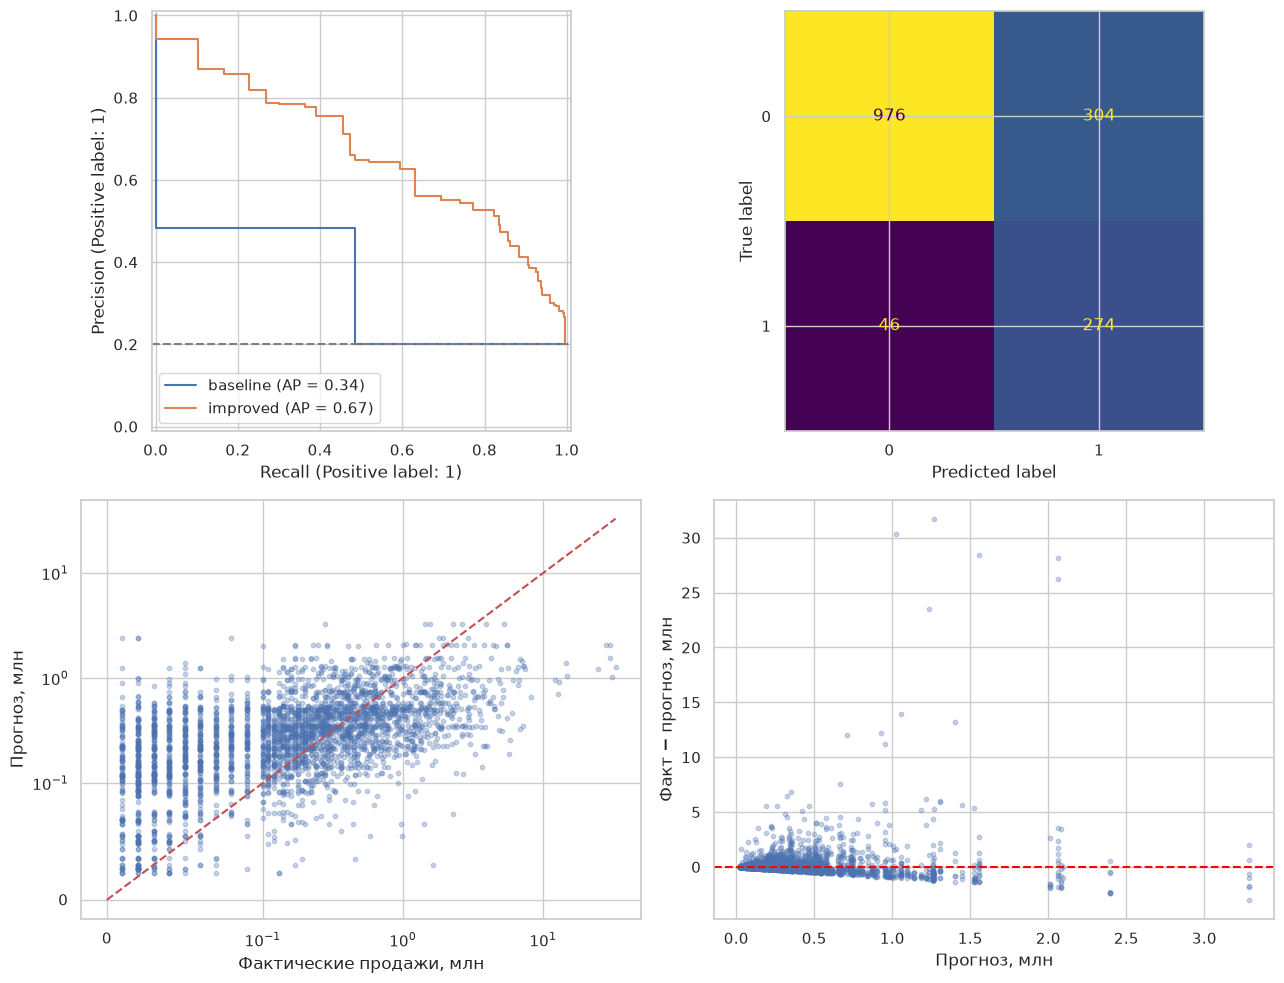

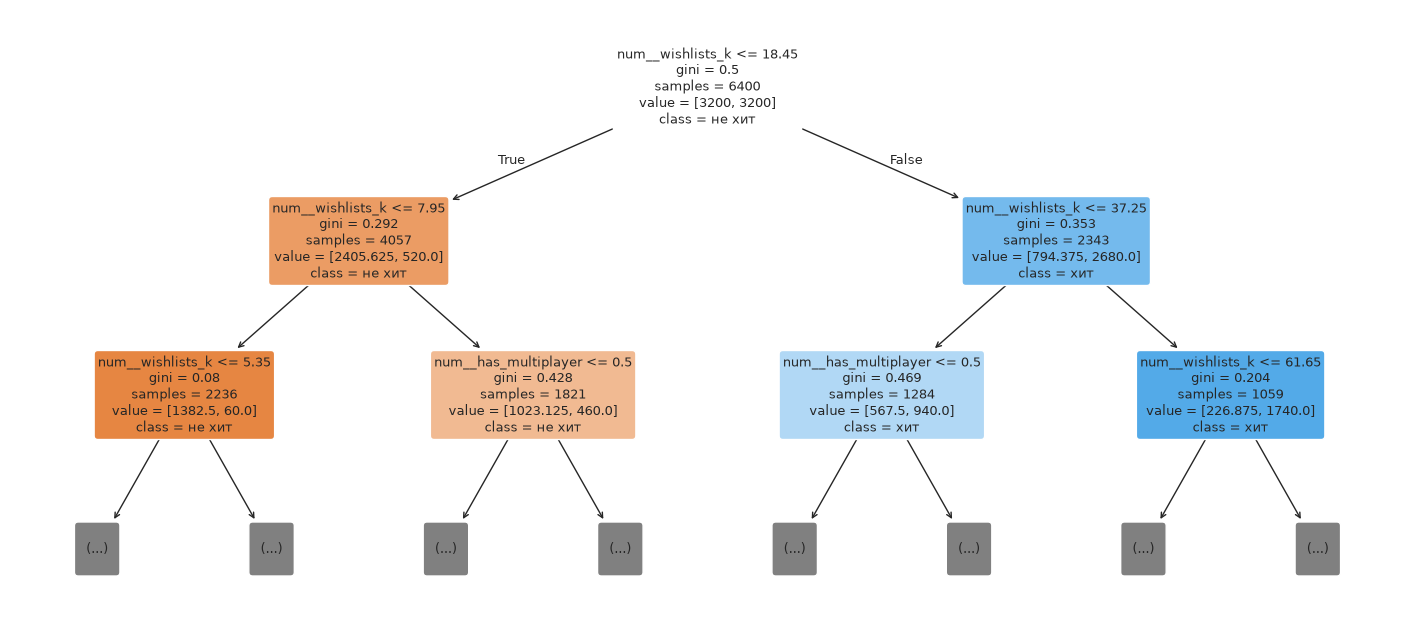

,Важность по снижению нечистоты
num__wishlists_k,0.904216
num__trailer_views_k,0.041297
num__has_multiplayer,0.034547
num__team_size,0.005710
num__languages_supported,0.003075
cat__genre_Shooter,0.002893
num__controller_support,0.002839
num__file_size_gb,0.002825
num__price_usd,0.002023
num__release_year,0.000576


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for stage in ["baseline", "improved"]:
    PrecisionRecallDisplay.from_predictions(yc_test, predictions[("c", "sklearn " + stage)][1], name=stage, ax=axes[0, 0])
axes[0, 0].axhline(yc_test.mean(), color="gray", linestyle="--")
ConfusionMatrixDisplay.from_predictions(yc_test, predictions[("c", "sklearn improved")][0], ax=axes[0, 1], colorbar=False)
pred = predictions[("r", "sklearn improved")]
axes[1, 0].scatter(yr_test, pred, alpha=.3, s=10)
axes[1, 0].plot([0, yr_test.max()], [0, yr_test.max()], "r--")
axes[1, 0].set_xscale("symlog", linthresh=.1); axes[1, 0].set_yscale("symlog", linthresh=.1)
axes[1, 0].set(xlabel="Фактические продажи, млн", ylabel="Прогноз, млн")
axes[1, 1].scatter(pred, yr_test.to_numpy()-pred, alpha=.3, s=10)
axes[1, 1].axhline(0, color="red", linestyle="--")
axes[1, 1].set(xlabel="Прогноз, млн", ylabel="Факт − прогноз, млн")
plt.tight_layout(); plt.show()
model = improved["c"]
feature_names = model.named_steps["prep"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(model.named_steps["model"], feature_names=feature_names, class_names=["не хит", "хит"],
          max_depth=2, filled=True, rounded=True, fontsize=9, ax=ax)
plt.show()
display(pd.Series(model.named_steps["model"].feature_importances_, index=feature_names,
                  name="Важность по снижению нечистоты").sort_values(ascending=False).head(12).to_frame())

### Выводы по пунктам 3g, 4e и 4j
Численные выводы формируются по фактическим результатам. Сравниваем улучшение относительно исходного дерева, отличие собственной модели от sklearn и преимущество над Dummy отдельно.

Дерево ограниченной сложности может давать более устойчивые вероятности, но AP и F1 не обязаны расти одновременно. Для продаж логарифмирование меняет обучающий критерий: MAE и RMSE необходимо рассматривать совместно. Разные правила разрешения ничьих и численные допуски объясняют возможность разных структур CART при одной постановке; это не основание требовать полного совпадения тестовых метрик, но и само по себе не доказывает корректность реализации — для неё выше выполнены отдельные проверки.

Один holdout не доказывает статистическую значимость. CV после выбора параметров может быть оптимистична; тест оценивается отдельно. Результаты Steam относятся к синтетическим данным, а исторические продажи — к отобранным играм и разным срокам накопления продаж. Для практического применения нужен временной эксперимент с реальными дорелизными признаками и единым горизонтом наблюдения.

In [13]:
for task, metric, label in [("c", "AP", "Классификация"), ("r", "MAE", "Регрессия")]:
    tab = metrics[metrics.task == task].set_index("model")
    a, b = tab.loc["sklearn baseline", metric], tab.loc["sklearn improved", metric]
    u, v = tab.loc["numpy baseline", metric], tab.loc["numpy improved", metric]
    gain = b-a if task == "c" else a-b
    own_gain = v-u if task == "c" else u-v
    dummy = tab.loc["Dummy", metric]
    beats_dummy = b > dummy if task == "c" else b < dummy
    display(Markdown(f"**{label}.** Выбрано по CV: `{selected[task]}`. "
        f"sklearn {metric}: {a:.5f} → {b:.5f} (выигрыш {gain:+.5f}); "
        f"NumPy: {u:.5f} → {v:.5f} (выигрыш {own_gain:+.5f}). "
        f"NumPy improved минус sklearn improved: {v-b:+.6f}. "
        f"Dummy: {dummy:.5f}. "
        + ("Улучшенная sklearn-модель превзошла Dummy." if beats_dummy else "Улучшенная sklearn-модель не превзошла Dummy по основной метрике.")
        + (" Перенос улучшений в NumPy дал выигрыш." if own_gain > 0 else " Перенос улучшений не дал выигрыша в NumPy на этом тесте.")))
r = metrics[metrics.task == "r"].set_index("model")
a, b = r.loc["sklearn baseline", "RMSE"], r.loc["sklearn improved", "RMSE"]
display(Markdown(f"**Компромисс регрессии:** RMSE {a:.5f} → {b:.5f} млн копий. "
    + ("Крупные ошибки уменьшились вместе с выбранным улучшением." if b < a else "Улучшение по основной метрике не означает уменьшения крупных ошибок.")))

**Классификация.** Выбрано по CV: `H2 tuned raw`. sklearn AP: 0.33701 → 0.66975 (выигрыш +0.33273); NumPy: 0.35266 → 0.66975 (выигрыш +0.31709). NumPy improved минус sklearn improved: +0.000004. Dummy: 0.20000. Улучшенная sklearn-модель превзошла Dummy. Перенос улучшений в NumPy дал выигрыш.

**Регрессия.** Выбрано по CV: `H3 tuned log target`. sklearn MAE: 0.53334 → 0.44497 (выигрыш +0.08836); NumPy: 0.52887 → 0.44497 (выигрыш +0.08390). NumPy improved минус sklearn improved: +0.000000. Dummy: 0.45618. Улучшенная sklearn-модель превзошла Dummy. Перенос улучшений в NumPy дал выигрыш.

**Компромисс регрессии:** RMSE 1.52165 → 1.50475 млн копий. Крупные ошибки уменьшились вместе с выбранным улучшением.